## Reily Fairchild -- Tipping Point Community Technical Interview 

Instructions
- Conduct basic data checks to understand the structure of the dataset.
- Create a variable called “Relative Year”, defined as the earnings year minus the client's
cohort year. Year 0 is the year the client entered the program, negative values are
before, positive values are after.
- Create a measure of annual earnings for each client in each year.
- Do any necessary data cleaning.
- In whatever visualization tool you’re most comfortable, create a few charts. Make them
legible to a program officer who does not work in data. These charts should include:
○ Earnings by relative year
○ Earnings by two demographic groups of your choosing. You can pick from race
and ethnicity, gender, age, education, and disability status.

- Feel free to include any additional data that you think may be useful for context or
understanding.
- For each of these charts help us interpret what the data means. What are the key
takeaways? What additional questions does it raise?
What to send back
- Your three charts with written responses. Keep this brief under 200 words or 7 bullet
points.

### HOW TO READ THIS FILE	

**What this is**	  Quarterly wage records for people who went through a workforce training program, matched to state unemployment insurance wage records. Every value in this file is sample data.

**What one row is**	  One client, in one calendar quarter, in one dataset version. A client with three years of wage history appears on many rows.
    
**Unique key**	  ClientID + DatasetVersion + Year + Quarter.

**The six dataset versions**	   The file is six stacked slices of the same underlying wage records. Each slice carries one demographic field and leaves the others blank. 
The same client and the same quarter can appear in more than one version, with the same earnings value on each.
- Version 0 is the base slice with no demographics. 
- Versions 1 through 5 each add Race/Ethnicity, Gender, Age, Education, or Disability. 
	
#### COLUMNS	

- **Column**	 What it means
- **ClientID**	De-identified identifier for one person.
- **Cohort**	Calendar year the client entered the program.
- **Participation**	Whether the client finished the program.
- **Program** 	The training or service track the client was enrolled in.
- **RaceEthnicity**	Self reported race and ethnicity, collected at program entry.
- **Gender**	Self reported gender, collected at program entry.
- **AgeBracket**	Age band at program entry.    
- **EducationAttainment**	Highest level of education completed at program entry.  
- **DisabilityStatus**	Self reported disability status at program entry.    
- **DatasetVersion**	Each research question gets its own version of the dataset, built from the same clients and the same base variables with one added demographic variable. Grantees build these versions separately and then append them into a single tab before sending the file to EDD, which is why one client and one quarter can appear on more than one row here. This field names which version a row came from. Version 0 is the base slice, and Versions 1 through 5 each add a single demographic. Since every version repeats the same underlying wage records, filter to one version before counting anything.
- **FinalStatus**	Whether the data provider returns the row or drops it. The data provider drops anyone whose exact combination of characteristics is shared by fewer than 10 people in that dataset version, so no one can be identified from the file. It also drops people it could not find a wage record for. Dropped rows come back with no earnings.
- **Year**	Calendar year of the earnings quarter.
- **Quarter**	Calendar quarter of the earnings record.
- **Quarterly Earnings ($)**	Total wages reported to the state for that client in that quarter.

### Data Exploration


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sample_dataset = "data/Data_Analytics_Associate_Activity_Sample_Dataset_gsheet.xlsx"
df = pd.read_excel(sample_dataset, sheet_name=1)

In [3]:
df

,ClientID,Cohort,Participation,Program,RaceEthnicity,Gender,AgeBracket,EducationAttainment,DisabilityStatus,DatasetVersion,FinalStatus,Year,Quarter,Quarterly Earnings ($)
0,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2015.0,4.0,4047.0
1,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2016.0,1.0,5036.0
2,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2016.0,4.0,5261.0
3,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,2.0,4215.0
4,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,3.0,4410.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71063,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2021.0,3.0,5207.0
71064,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2021.0,4.0,6116.0
71065,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,1.0,4993.0
71066,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,2.0,6368.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71068 entries, 0 to 71067
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ClientID                71068 non-null  object 
 1   Cohort                  71068 non-null  int64  
 2   Participation           71068 non-null  object 
 3   Program                 71068 non-null  object 
 4   RaceEthnicity           8349 non-null   object 
 5   Gender                  12463 non-null  object 
 6   AgeBracket              12149 non-null  object 
 7   EducationAttainment     9174 non-null   object 
 8   DisabilityStatus        12592 non-null  object 
 9   DatasetVersion          71068 non-null  object 
 10  FinalStatus             71068 non-null  object 
 11  Year                    66986 non-null  float64
 12  Quarter                 66986 non-null  float64
 13  Quarterly Earnings ($)  66986 non-null  float64
dtypes: float64(3), int64(1), object(10)
me

In [5]:
df.describe()

,Cohort,Year,Quarter,Quarterly Earnings ($)
count,71068.000000,66986.000000,66986.000000,66986.000000
mean,2019.295646,2019.839907,2.537157,6790.575434
std,1.371117,2.412048,1.121452,1631.411053
min,2015.000000,2012.000000,1.000000,3237.000000
25%,2018.000000,2018.000000,2.000000,5549.000000
50%,2019.000000,2020.000000,3.000000,6573.000000
75%,2021.000000,2022.000000,4.000000,7821.000000
max,2021.000000,2024.000000,4.000000,13957.000000


In [6]:
cols_list = df.columns.tolist()
cols_list

['ClientID',
 'Cohort',
 'Participation',
 'Program',
 'RaceEthnicity',
 'Gender',
 'AgeBracket',
 'EducationAttainment',
 'DisabilityStatus',
 'DatasetVersion',
 'FinalStatus',
 'Year',
 'Quarter',
 'Quarterly Earnings ($)']

In [7]:
# confirming there are no duplicates or typos within rows
for c in cols_list:
    print(c)
    print(df[c].unique())

ClientID
['SAMPLE-10000' 'SAMPLE-10001' 'SAMPLE-10002' ... 'SAMPLE-11369'
 'SAMPLE-11370' 'SAMPLE-11371']
Cohort
[2018 2019 2020 2015 2017 2016 2021]
Participation
['Completed' 'Did Not Complete']
Program
['Parent Career Readiness' 'Advanced Technical Training Track'
 'Nursing Skills Refresher, Urban Campus' 'Dental Support Certificate'
 'Medical Assistant Certificate, Health System A'
 'Medical Assistant Refresher, Health System A'
 'Financial Services Academy' 'Office Careers Bridge'
 'Licensed Dental Assistant Track'
 'Medical Assistant Certificate, University Partner'
 'Phlebotomy Technician Certificate, Health System A'
 'Data Analytics Track'
 'Medical Assistant Certificate, Academic Medical Center'
 'Medical Assistant Refresher, Medical Group C'
 'Medical Assistant Certificate, Regional Campus'
 'Public Utility Internship' 'Clinical Partner Program, Health System B'
 'Veterans Services Track' 'Medical Assistant Refresher, Health System B'
 'Medical Assistant Certificate, Health 

In [8]:
df_dropped = df[df['FinalStatus'].isin(['Dropped - Group Below 10', 'Dropped - Unmatched'])]

df_dropped.groupby('ClientID').first()

cat_cols = ['Participation', 'Program', 'RaceEthnicity', 'Gender', 'AgeBracket',
            'EducationAttainment', 'DisabilityStatus', 'DatasetVersion', 'FinalStatus']

for col in cat_cols:
    print(f"\n--- {col} ---")
    pct = df_dropped[col].value_counts(normalize=True, dropna=False).mul(100).round(1)
    print(pct.astype(str) + '%')


--- Participation ---
Participation
Completed           73.8%
Did Not Complete    26.2%
Name: proportion, dtype: object

--- Program ---
Program
Parent Career Readiness                                   20.2%
Dental Support Certificate                                11.7%
Office Careers Bridge                                     10.9%
Nursing Skills Refresher, Urban Campus                     8.9%
Financial Services Academy                                 8.5%
Medical Assistant Certificate, University Partner          7.0%
Medical Assistant Refresher, Health System A               6.6%
Medical Assistant Certificate, Health System A             6.2%
Advanced Technical Training Track                          5.8%
Medical Assistant Certificate, Academic Medical Center     3.1%
Licensed Dental Assistant Track                            2.9%
Data Analytics Track                                       2.8%
Phlebotomy Technician Certificate, Health System A         1.5%
Phlebotomy Technician 

In [9]:
df_included = df[df['FinalStatus'].isin(['Included'])]
df_included.groupby('ClientID').first()


# running short on time so used AI for this code
cat_cols = ['Participation', 'Program', 'RaceEthnicity', 'Gender', 'AgeBracket',
            'EducationAttainment', 'DisabilityStatus', 'DatasetVersion', 'FinalStatus']

for col in cat_cols:
    print(f"\n--- {col} ---")
    pct = df_included[col].value_counts(normalize=True, dropna=False).mul(100).round(1)
    print(pct.astype(str) + '%')


--- Participation ---
Participation
Completed           94.5%
Did Not Complete     5.5%
Name: proportion, dtype: object

--- Program ---
Program
Parent Career Readiness                              76.3%
Dental Support Certificate                           11.2%
Office Careers Bridge                                 6.3%
Financial Services Academy                            2.3%
Medical Assistant Certificate, University Partner     1.2%
Nursing Skills Refresher, Urban Campus                1.1%
Medical Assistant Refresher, Health System A          0.8%
Advanced Technical Training Track                     0.5%
Medical Assistant Certificate, Health System A        0.3%
Name: proportion, dtype: object

--- RaceEthnicity ---
RaceEthnicity
NaN                                    88.9%
White                                   3.9%
Asian                                   2.7%
Hispanic, Latino, or Spanish Origin     2.4%
Black or African American               1.7%
African American or Black    

In [10]:
# are there certain demographics more likely to be dropped than others?

In [11]:
df_notComplete = df[df['Participation'] == 'Did Not Complete']
df_notComplete

,ClientID,Cohort,Participation,Program,RaceEthnicity,Gender,AgeBracket,EducationAttainment,DisabilityStatus,DatasetVersion,FinalStatus,Year,Quarter,Quarterly Earnings ($)
159,SAMPLE-10012,2016,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Dropped - Group Below 10,NaN,NaN,NaN
160,SAMPLE-10013,2017,Did Not Complete,Dental Support Certificate,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Dropped - Group Below 10,NaN,NaN,NaN
267,SAMPLE-10022,2020,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,2.0,3940.0
268,SAMPLE-10022,2020,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,4.0,5150.0
269,SAMPLE-10022,2020,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2018.0,2.0,4642.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71027,SAMPLE-11368,2019,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2021.0,4.0,6854.0
71028,SAMPLE-11368,2019,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,1.0,6829.0
71029,SAMPLE-11368,2019,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,2.0,6891.0
71030,SAMPLE-11368,2019,Did Not Complete,Parent Career Readiness,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,3.0,6208.0


In [12]:
df_complete = df[df['Participation'] == 'Completed']
df_final = df_complete[df_complete['FinalStatus'] == 'Included']
df_final

,ClientID,Cohort,Participation,Program,RaceEthnicity,Gender,AgeBracket,EducationAttainment,DisabilityStatus,DatasetVersion,FinalStatus,Year,Quarter,Quarterly Earnings ($)
0,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2015.0,4.0,4047.0
1,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2016.0,1.0,5036.0
2,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2016.0,4.0,5261.0
3,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,2.0,4215.0
4,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,3.0,4410.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71063,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2021.0,3.0,5207.0
71064,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2021.0,4.0,6116.0
71065,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,1.0,4993.0
71066,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,2.0,6368.0


In [13]:
# Representation of final dataset used in analysis

cat_cols = ['Participation', 'Program', 'RaceEthnicity', 'Gender', 'AgeBracket',
            'EducationAttainment', 'DisabilityStatus', 'DatasetVersion', 'FinalStatus']

for col in cat_cols:
    print(f"\n--- {col} ---")
    pct = df_final[col].value_counts(normalize=True, dropna=False).mul(100).round(1)
    print(pct.astype(str) + '%')


--- Participation ---
Participation
Completed    100.0%
Name: proportion, dtype: object

--- Program ---
Program
Parent Career Readiness                              74.9%
Dental Support Certificate                           11.9%
Office Careers Bridge                                 6.6%
Financial Services Academy                            2.5%
Medical Assistant Certificate, University Partner     1.3%
Nursing Skills Refresher, Urban Campus                1.2%
Medical Assistant Refresher, Health System A          0.9%
Advanced Technical Training Track                     0.5%
Medical Assistant Certificate, Health System A        0.3%
Name: proportion, dtype: object

--- RaceEthnicity ---
RaceEthnicity
NaN                                    88.5%
White                                   4.2%
Asian                                   2.9%
Hispanic, Latino, or Spanish Origin     2.5%
Black or African American               1.7%
African American or Black               0.3%
Name: proportion

### Relative Year
- Create a variable called “Relative Year”, defined as the earnings year minus the client's
cohort year. Year 0 is the year the client entered the program, negative values are
before, positive values are after.

In [14]:
df_final['Relative Year'] = df_final['Year'] - df_final['Cohort']
df_final

/tmp/ipykernel_1756/4093733362.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Relative Year'] = df_final['Year'] - df_final['Cohort']


,ClientID,Cohort,Participation,Program,RaceEthnicity,Gender,AgeBracket,EducationAttainment,DisabilityStatus,DatasetVersion,FinalStatus,Year,Quarter,Quarterly Earnings ($),Relative Year
0,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2015.0,4.0,4047.0,-3.0
1,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2016.0,1.0,5036.0,-2.0
2,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2016.0,4.0,5261.0,-2.0
3,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,2.0,4215.0,-1.0
4,SAMPLE-10000,2018,Completed,Parent Career Readiness,NaN,NaN,NaN,NaN,NaN,"Version 0 - Completion Status (Base, Required)",Included,2017.0,3.0,4410.0,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71063,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2021.0,3.0,5207.0,2.0
71064,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2021.0,4.0,6116.0,2.0
71065,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,1.0,4993.0,3.0
71066,SAMPLE-11371,2019,Completed,Dental Support Certificate,NaN,NaN,NaN,NaN,Disabled,Version 5 - Disability,Included,2022.0,2.0,6368.0,3.0


### Annual Earnings
- Create a measure of annual earnings for each client in each year.

In [16]:
# summing by quarter as well, would want to see that is the same number of quarters represented
def annualEarnings_by_dataset(version, dem_col = None):
    df_version = df_final[df_final['DatasetVersion'] == version]
    if version == 'Version 0 - Completion Status (Base, Required)':
        df_client_annualEarning = df_version.groupby(['ClientID', 'Year']).agg({
           'Quarter': 'count',
            'Quarterly Earnings ($)' : 'sum',
            'Relative Year' : 'first',
            'Program' : 'first'
        }).rename(columns={'Quarter' : 'Quarters tracked in year', 'Quarterly Earnings ($)' : 'Annual Earnings ($)'})
    else:
        df_client_annualEarning = df_version.groupby(['ClientID', 'Year']).agg({
           'Quarter': 'count',
            'Quarterly Earnings ($)' : 'sum',
            'Relative Year' : 'first',
            'Program' : 'first',
            dem_col: 'first' #demographic column in version
        }).rename(columns={'Quarter' : 'Quarters tracked in year', 'Quarterly Earnings ($)' : 'Annual Earnings ($)'})
        
    return df_client_annualEarning


In [17]:
df_client_annualEarning = annualEarnings_by_dataset('Version 0 - Completion Status (Base, Required)')
df_client_annualEarning

Quarters tracked in year  Annual Earnings ($)  \
ClientID     Year                                                    
SAMPLE-10000 2015.0                         1               4047.0   
             2016.0                         2              10297.0   
             2017.0                         2               8625.0   
             2018.0                         3              14147.0   
             2019.0                         3              14016.0   
...                                       ...                  ...   
SAMPLE-11371 2018.0                         3              14077.0   
             2019.0                         2              10068.0   
             2020.0                         2              10891.0   
             2021.0                         3              16456.0   
             2022.0                         3              16518.0   

                     Relative Year                     Program  
ClientID     Year                                               
SAMPLE-10000 2015.0           -3.0     Parent Career Readiness  
             2016.0           -2.0     Parent Career Readiness  
             2017.0           -1.0     Parent Career Readiness  
             2018.0            0.0     Parent Career Readiness  
             2019.0            1.0     Parent Career Readiness  
...                            ...                         ...  
SAMPLE-11371 2018.0           -1.0  Dental Support Certificate  
             2019.0            0.0  Dental Support Certificate  
             2020.0            1.0  Dental Support Certificate  
             2021.0            2.0  Dental Support Certificate  
             2022.0            3.0  Dental Support Certificate  

[5965 rows x 4 columns]

### Data Visualizations
Create 3 charts. These charts should include: 
- Earnings by relative year 
- Earnings by two demographic groups of your choosing. You can pick from race and ethnicity, gender, age, education, and disability status.

Feel free to include any additional data that you think may be useful for context or understanding. For each of these charts help us interpret what the data means. What are the key takeaways? What additional questions does it raise? What to send back: Your three charts with written responses. Keep this brief under 200 words or 7 bullet points.

#### General trends: earnings by year for all cohorts


In [18]:
# Whisker plot by relative year.

In [19]:
annualEarning_ungroup = df_client_annualEarning.reset_index()
annualEarning_ungroup

,ClientID,Year,Quarters tracked in year,Annual Earnings ($),Relative Year,Program
0,SAMPLE-10000,2015.0,1,4047.0,-3.0,Parent Career Readiness
1,SAMPLE-10000,2016.0,2,10297.0,-2.0,Parent Career Readiness
2,SAMPLE-10000,2017.0,2,8625.0,-1.0,Parent Career Readiness
3,SAMPLE-10000,2018.0,3,14147.0,0.0,Parent Career Readiness
4,SAMPLE-10000,2019.0,3,14016.0,1.0,Parent Career Readiness
...,...,...,...,...,...,...
5960,SAMPLE-11371,2018.0,3,14077.0,-1.0,Dental Support Certificate
5961,SAMPLE-11371,2019.0,2,10068.0,0.0,Dental Support Certificate
5962,SAMPLE-11371,2020.0,2,10891.0,1.0,Dental Support Certificate
5963,SAMPLE-11371,2021.0,3,16456.0,2.0,Dental Support Certificate


In [20]:
earnings_relativeYear = annualEarning_ungroup.groupby(['Relative Year'])['Annual Earnings ($)'].mean()

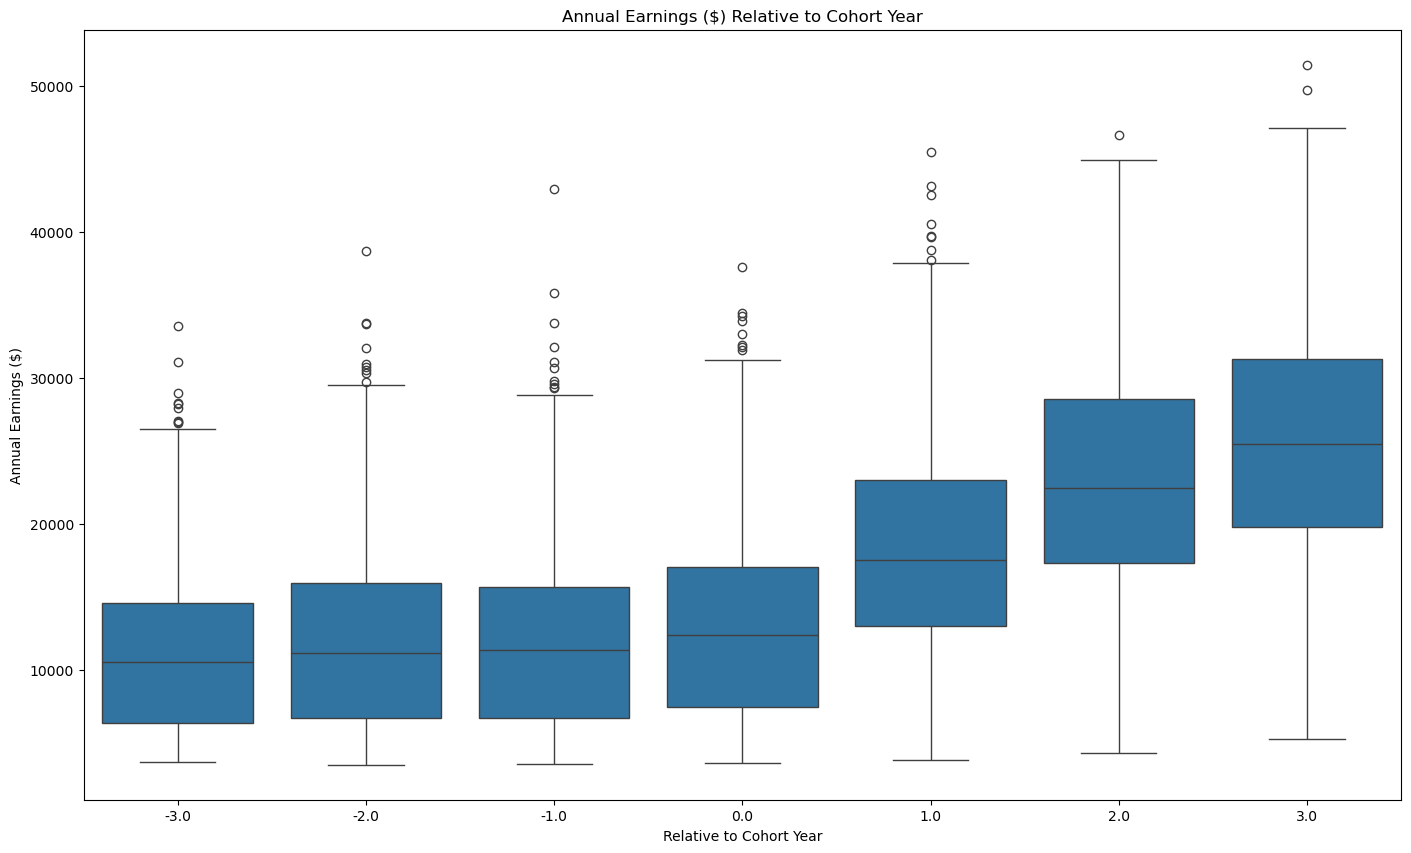

In [63]:

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(17, 10))
sns.boxplot(data=annualEarning_ungroup, x='Relative Year', y='Annual Earnings ($)')

plt.title('Annual Earnings ($) Relative to Cohort Year')
plt.suptitle('')  # Removes the automatic default sub-title
plt.xlabel('Relative to Cohort Year')
plt.ylabel('Annual Earnings ($)')
fig.savefig('figures/AnnualEarnings_by_RelativeYear', bbox_inches='tight')
plt.show()

In [64]:
## question: is our data less complete for years prior to cohort year? Potential there are less quarters tracked for negative relative years, making the reporting less accurate.  

In [65]:
## What if we only considered clients who quarter reporting was 4 each year?

In [66]:
# how many women and men participated in the cohort?

## Earnings by Race

In [67]:
df_race_annualEarning = annualEarnings_by_dataset('Version 1 - Race/Ethnicity', dem_col='RaceEthnicity')
df_race = df_race_annualEarning.reset_index()
df_race

,ClientID,Year,Quarters tracked in year,Annual Earnings ($),Relative Year,Program,RaceEthnicity
0,SAMPLE-10002,2017.0,1,5104.0,-3.0,Parent Career Readiness,Asian
1,SAMPLE-10002,2018.0,1,4390.0,-2.0,Parent Career Readiness,Asian
2,SAMPLE-10002,2019.0,3,15184.0,-1.0,Parent Career Readiness,Asian
3,SAMPLE-10002,2020.0,2,9105.0,0.0,Parent Career Readiness,Asian
4,SAMPLE-10002,2022.0,3,17785.0,2.0,Parent Career Readiness,Asian
...,...,...,...,...,...,...,...
2962,SAMPLE-11370,2020.0,2,10705.0,-1.0,Parent Career Readiness,Black or African American
2963,SAMPLE-11370,2021.0,1,4612.0,0.0,Parent Career Readiness,Black or African American
2964,SAMPLE-11370,2022.0,3,17979.0,1.0,Parent Career Readiness,Black or African American
2965,SAMPLE-11370,2023.0,4,24608.0,2.0,Parent Career Readiness,Black or African American


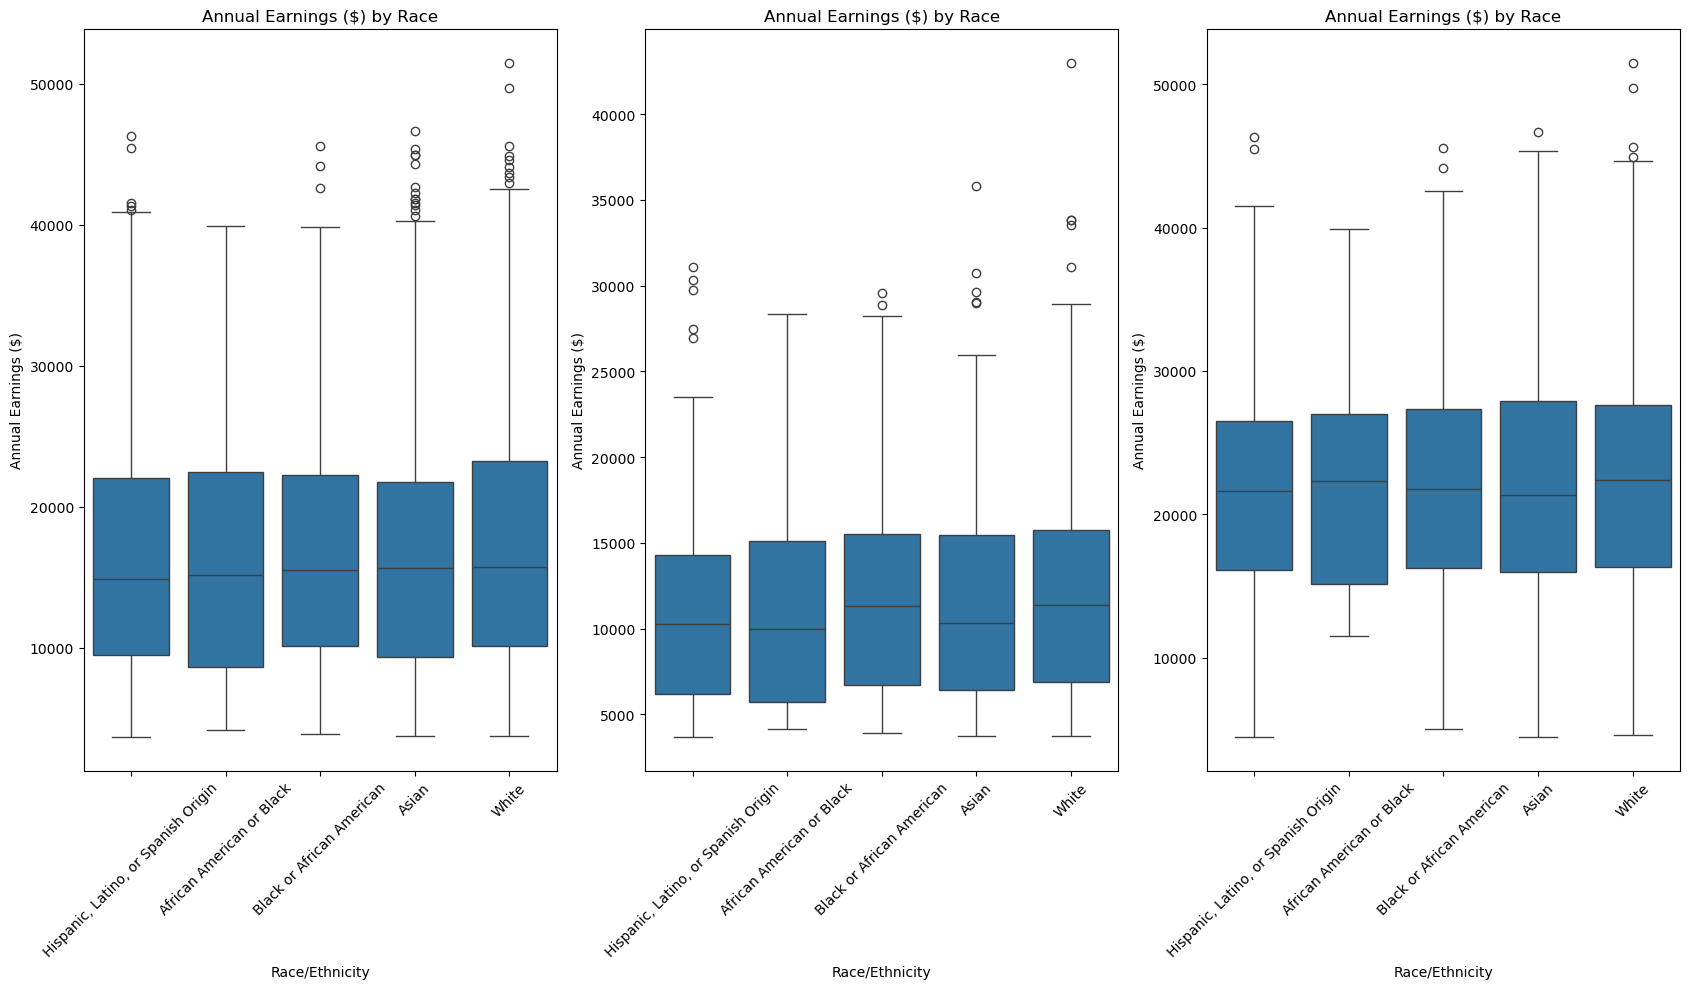

In [68]:
df_race_annualEarning = annualEarnings_by_dataset('Version 1 - Race/Ethnicity', 'RaceEthnicity')
df_race = df_race_annualEarning.reset_index()

median_order = df_race.groupby('RaceEthnicity')['Annual Earnings ($)'].median().sort_values().index

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17, 10))

sns.boxplot(data=df_race, x='RaceEthnicity', y='Annual Earnings ($)', order=median_order, ax = axes[0])
axes[0].set_title('Annual Earnings ($) by Race')
axes[0].set_xlabel('Race/Ethnicity')
axes[0].set_ylabel('Annual Earnings ($)')
axes[0].tick_params(axis="x", labelrotation=45)


# earning differentials before starting
df_race_preCohort = df_race[df_race['Relative Year'] < 0]
sns.boxplot(data=df_race_preCohort, x='RaceEthnicity', y='Annual Earnings ($)', order=median_order, ax = axes[1])
axes[1].set_title('Annual Earnings ($) by Race')
axes[1].set_xlabel('Race/Ethnicity')
axes[1].set_ylabel('Annual Earnings ($)')
axes[1].tick_params(axis="x", labelrotation=45)

df_race_postCohort = df_race[df_race['Relative Year'] > 0]
sns.boxplot(data=df_race_postCohort, x='RaceEthnicity', y='Annual Earnings ($)', order=median_order, ax = axes[2])
axes[2].set_title('Annual Earnings ($) by Race')
axes[2].set_xlabel('Race/Ethnicity')
axes[2].set_ylabel('Annual Earnings ($)')
axes[2].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
fig.savefig('figures/AnnualEarnings_by_Race', bbox_inches='tight')
plt.show()

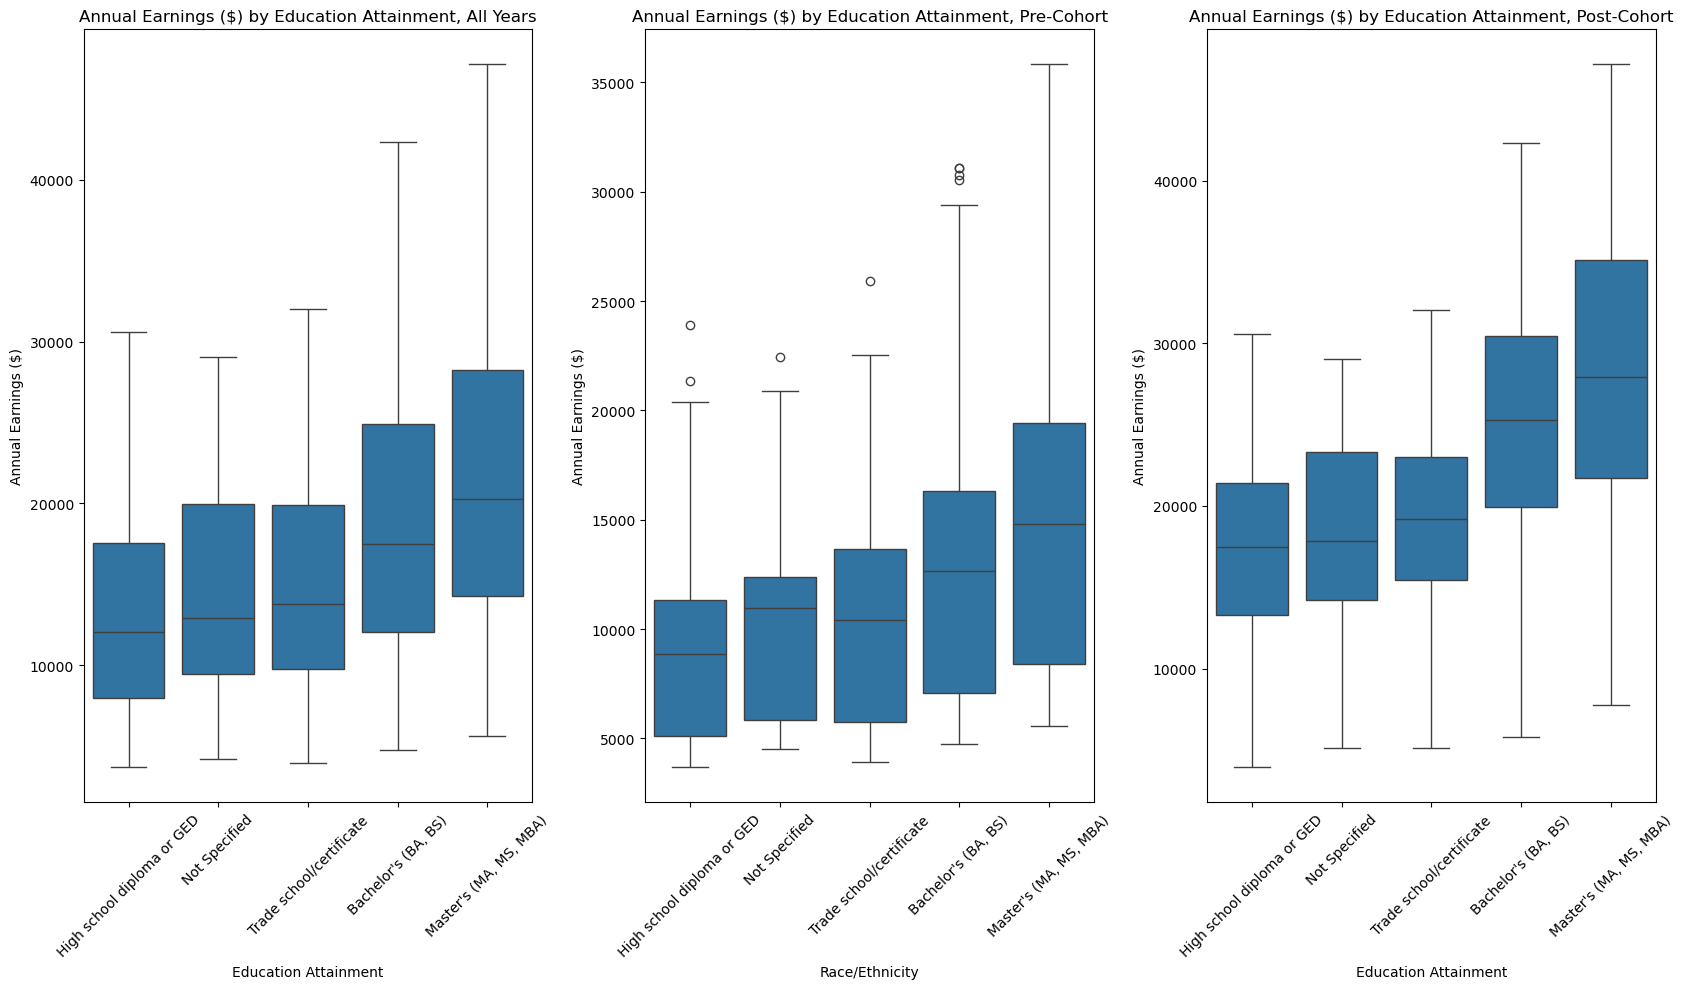

In [69]:
df_education_annualEarning = annualEarnings_by_dataset('Version 4 - Education', 'EducationAttainment')
df_education = df_education_annualEarning.reset_index()

median_order = df_education.groupby('EducationAttainment')['Annual Earnings ($)'].median().sort_values().index

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17, 10))

sns.boxplot(data=df_education, x='EducationAttainment', y='Annual Earnings ($)', order=median_order, ax = axes[0])
axes[0].set_title('Annual Earnings ($) by Education Attainment, All Years')
axes[0].set_xlabel('Education Attainment')
axes[0].set_ylabel('Annual Earnings ($)')
axes[0].tick_params(axis="x", labelrotation=45)


# earning differentials before starting
df_race_preCohort = df_education[df_education['Relative Year'] < 0]
sns.boxplot(data=df_race_preCohort, x='EducationAttainment', y='Annual Earnings ($)', order=median_order, ax = axes[1])
axes[1].set_title('Annual Earnings ($) by Education Attainment, Pre-Cohort')
axes[1].set_xlabel('Race/Ethnicity')
axes[1].set_ylabel('Annual Earnings ($)')
axes[1].tick_params(axis="x", labelrotation=45)

df_race_postCohort = df_education[df_education['Relative Year'] > 0]
sns.boxplot(data=df_race_postCohort, x='EducationAttainment', y='Annual Earnings ($)', order=median_order, ax = axes[2])
axes[2].set_title('Annual Earnings ($) by Education Attainment, Post-Cohort')
axes[2].set_xlabel('Education Attainment')
axes[2].set_ylabel('Annual Earnings ($)')
axes[2].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
fig.savefig('figures/AnnualEarnings_by_Education', bbox_inches='tight')
plt.show()